# 01 - Fairness fundamentals

**What you'll learn**
- What *privileged / unprivileged* groups are and how `callmefair` encodes them
- How to split data and train a model with `BMInterface`
- How the fairness metrics SPD and DI are computed (by hand, then with `BMMetrics`)
- How five metrics are combined into one fairness score
- Why the choice of privileged group changes the sign of a metric

**Prerequisite:** [00_data_and_preprocessing.ipynb](00_data_and_preprocessing.ipynb) (how the data was cleaned and how groups are defined). **Runtime:** about 1 minute.

## 1. Setup

In [1]:
from fhg_examples import setup
setup()

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from callmefair import BMInterface, BMMetrics, calculate_fairness_score
from fhg_examples.datasets import load, SPECS

## 2. The data and the two groups

We use the *Stroke prediction* data (5,109 patients). The label `stroke` is 1 when the patient had a stroke (only 4.87% do).
Fairness is always measured with respect to a **sensitive attribute**, here `age`. `callmefair` expects it to be binary:
value **1 = privileged group** (65 or older), value **0 = unprivileged group** (younger than 65).
"Privileged" is a convention for the reference group, not a judgement. See `00_data_and_preprocessing.ipynb` for how these groups were built.

In [2]:
df = load('stroke')
spec = SPECS['stroke']
privileged_group, unprivileged_group = spec.attribute('age').groups
print(privileged_group, unprivileged_group)
print(df.shape)

[{'age': 1}] [{'age': 0}]
(5109, 18)


A first look at the groups: their size and their **base rate** (share of patients with label 1). If base rates differ a lot, even a perfect model would produce different positive rates.

**Caveat.** Much of this gap reflects real clinical risk: age is a stroke risk factor. A base-rate difference is not by itself unfair; the fairness question is whether the model's errors and decisions are distributed equitably across the groups, which is what EOD and AOD capture.

In [3]:
groups = df.groupby('age')['stroke'].agg(patients='size', base_rate='mean')
groups.index = groups.index.map({1: '1 (65 or older, privileged)', 0: '0 (younger, unprivileged)'})
groups

,patients,base_rate
age,,
"0 (younger, unprivileged)",4082,0.022
"1 (65 or older, privileged)",1027,0.155


## 3. Split the data with `BMInterface`

`BMInterface` makes a stratified **train / validation / test** split (80 / 10 / 10 by default; here we use 60 / 20 / 20) and wraps each part as an AIF360 dataset.
The model learns on *train*, the decision threshold is chosen on *validation*, and all fairness numbers are measured on *test*.

With only 249 stroke cases, the default 10% splits would leave very few positives per group in validation and test, so we enlarge them to 20% each to get enough positive cases per group for stable rates.

In [4]:
bmI = BMInterface(df, label=spec.label, protected=['age'], test_size=0.2, val_size=0.2, random_state=42)
X_train, y_train = bmI.get_train_xy()
X_val, _ = bmI.get_val_xy()
X_test, y_test = bmI.get_test_xy()
pd.Series({'train': len(X_train), 'validation': len(X_val), 'test': len(X_test)}, name='rows')

train         3065
validation    1022
test          1022
Name: rows, dtype: int64

## 4. Train a model and predict probabilities

Any classifier that returns probabilities works. A logistic regression is fast and enough for learning the concepts.

In [5]:
model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred_val = model.predict_proba(X_val)
pred_test = model.predict_proba(X_test)
pred_test[:3].round(3)   # columns follow model.classes_ = [0, 1]

array([[0.943, 0.057],
       [0.997, 0.003],
       [0.97 , 0.03 ]])

## 5. Two fairness metrics by hand

Turn probabilities into decisions with a threshold, then compare the **positive rate** (share of patients predicted 1) of the two groups:

- **SPD** (statistical parity difference) = rate(unprivileged) - rate(privileged). Ideal **0**; acceptable within (-0.1, 0.1).
- **DI** (disparate impact) = rate(unprivileged) / rate(privileged). Ideal **1**; acceptable within (0.8, 1.2).

First we need each test patient's group (1 = privileged, 0 = unprivileged). With a rare outcome a 0.5 threshold flags (almost) no one, which is why the threshold is tuned on validation:

In [6]:
test_age = bmI.get_test_BLD().protected_attributes.ravel()   # 1 = privileged, 0 = unprivileged
print('patients flagged at threshold 0.5:', int((pred_test[:, 1] > 0.5).sum()), 'of', len(test_age))

patients flagged at threshold 0.5: 0 of 1022


`BMMetrics` therefore uses the threshold that maximises **balanced accuracy** on the validation set, as the next section shows.

## 6. The same with `BMMetrics`

`BMMetrics` receives the validation and test probabilities, the `class_array` (`model.classes_`) and the two groups. It searches the threshold on validation and computes every metric on test.

In [7]:
bmM = BMMetrics(bmI, model.classes_, pred_val, pred_test, privileged_group, unprivileged_group)
print('threshold chosen on validation:', round(float(bmM.best_class_thresh), 3))

threshold chosen on validation: 0.04


The curves show why the threshold matters: balanced accuracy (top) and SPD (bottom) both change with it, and the dotted line marks the value picked on validation. The green band is the acceptable SPD range.

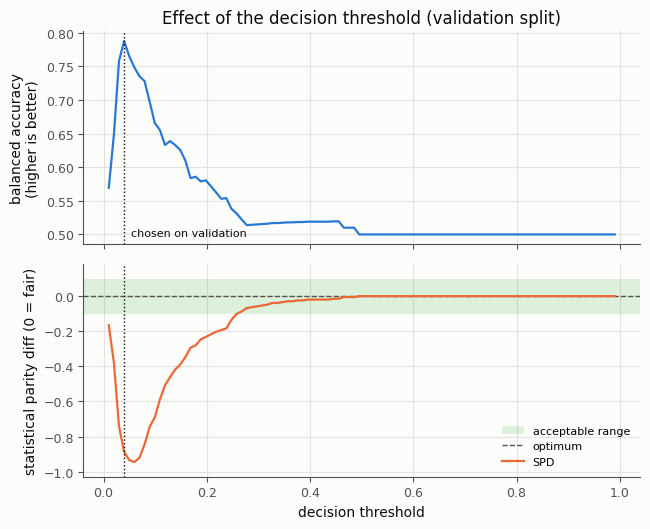

In [8]:
from callmefair.viz import plot_threshold_sweep
_ = plot_threshold_sweep(bmM, metric='spd')

To verify our understanding, recompute SPD and DI by hand using that same threshold and compare with `BMMetrics`.

In [9]:
decision = pred_test[:, 1] > bmM.best_class_thresh
rate_priv, rate_unpriv = decision[test_age == 1].mean(), decision[test_age == 0].mean()
print(f'by hand: SPD = {rate_unpriv - rate_priv:.3f}   DI = {rate_unpriv / rate_priv:.3f}')
rep = bmM.get_report()
print(f'BMMetrics: SPD = {rep["spd"]:.3f}   DI = {rep["disparate_impact"]:.3f}')

by hand: SPD = -0.888   DI = 0.112
BMMetrics: SPD = -0.888   DI = 0.112


The bars below show the three group rates behind the metrics, using the same tuned threshold. The gap in the first group of bars is the SPD computed above; the gap in the second is EOD (true positive rate).

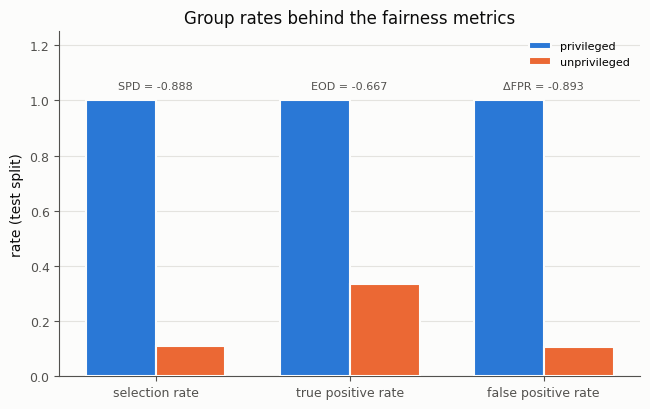

In [10]:
from callmefair.viz import plot_group_rates
_ = plot_group_rates(bmM)

## 7. The report: performance vs fairness

`get_report()` returns a dictionary. We split it into two tables: how *accurate* the model is, and how *fair* it is.

| Fairness metric | Meaning | Ideal | Acceptable |
|---|---|---|---|
| `eq_opp_diff` (EOD) | true-positive-rate gap between groups (unprivileged - privileged) | 0 | (-0.1, 0.1) |
| `avg_odd_diff` (AOD) | average of the true- and false-positive-rate gaps | 0 | (-0.1, 0.1) |
| `spd` (SPD) | gap in positive prediction rate | 0 | (-0.1, 0.1) |
| `disparate_impact` (DI) | ratio of positive prediction rates | 1 | (0.8, 1.2) |
| `theil_idx` (TI) | inequality of "benefit" across individuals | 0 | (0, 0.25) |

In [11]:
report = bmM.get_report()
perf_keys = ['balanced_acc', 'acc', 'precision', 'recall', 'f1', 'mcc']
fair_keys = ['eq_opp_diff', 'avg_odd_diff', 'spd', 'disparate_impact', 'theil_idx']
performance = pd.Series({k: report[k] for k in perf_keys}, name='performance (test set)').to_frame()
fairness = pd.Series({k: report[k] for k in fair_keys}, name='fairness (test set)').to_frame()
display(performance, fairness)

,performance (test set)
balanced_acc,0.772
acc,0.747
precision,0.138
recall,0.800
f1,0.236
mcc,0.084


,fairness (test set)
eq_opp_diff,-0.667
avg_odd_diff,-0.780
spd,-0.888
disparate_impact,0.112
theil_idx,0.064


The `spd` and `disparate_impact` values agree with our hand computation. Now the per-group rates behind them, from `bmM.cmetrics` (true positive rate = share of real strokes that the model flags):

In [12]:
cm = bmM.cmetrics
pd.DataFrame({'privileged (65+)': [cm.selection_rate(privileged=True), cm.true_positive_rate(privileged=True)],
              'unprivileged (<65)': [cm.selection_rate(privileged=False), cm.true_positive_rate(privileged=False)]},
             index=['selection rate', 'true positive rate']).round(3)

,privileged (65+),unprivileged (<65)
selection rate,1.0,0.112
true positive rate,1.0,0.333


**How to read this.** SPD and DI are dominated by the **base-rate gap**: older patients have far more strokes, so a sensible model flags them far more often, and a large SPD is expected here. The number to worry about is **EOD**: among patients who really had a stroke, the younger ones are flagged much less often (compare the two true positive rates), i.e. they are missed more. That error-driven harm, not the base-rate gap, is what mitigation in notebook 03 targets.

**Fair range view.** Each fairness metric is drawn against its acceptable range (green band): filled points are inside, hollow points outside (an arrow at the edge means far outside the plotted window). Here SPD and DI are out of range mostly because of the **base-rate gap** (older patients are flagged more because they have more strokes), while EOD and AOD are out of range because of **errors** (strokes among younger patients are missed more often). Only the Theil index stays inside.

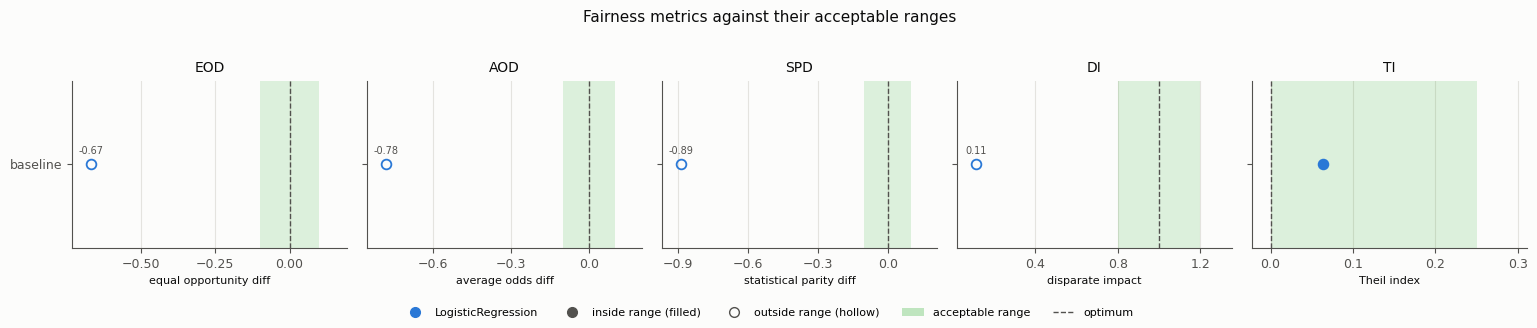

In [13]:
from callmefair.viz import plot_fair_ranges
baseline = [{**report, 'fair_score': bmM.get_score()['overall_score'], 'model': 'LogisticRegression', 'BM': 'baseline'}]
_ = plot_fair_ranges(baseline)

## 8. One number: the fairness score

Five metrics are hard to compare across models, so `calculate_fairness_score` merges them into a single score **between 0 and 1**
(**0 = perfectly fair, higher = more biased**). Each metric adds a penalty if it is outside its acceptable range, plus a penalty
proportional to its distance from the ideal. `bmM.get_score()` is a shortcut for passing the report's metrics.

In [14]:
score = calculate_fairness_score(EOD=report['eq_opp_diff'], AOD=report['avg_odd_diff'],
                                 SPD=report['spd'], DI=report['disparate_impact'],
                                 TI=report['theil_idx'])
print('overall_score:', score['overall_score'], '| is_fair:', score['is_fair'])
pd.DataFrame({'value': pd.Series({k: report[m] for k, m in zip(['EOD','AOD','SPD','DI','TI'], fair_keys)}),
              'in_range': score['metric_evaluations'], 'deviation': score['deviations']})

overall_score: 1.0 | is_fair: False


,value,in_range,deviation
EOD,-0.667,False,6.667
AOD,-0.780,False,7.796
SPD,-0.888,False,8.885
DI,0.112,False,4.442
TI,0.064,True,0.254


`deviation` is the distance from the ideal value in units of the acceptable half-width (1.0 means exactly on the edge of the acceptable range). `is_fair` is true only when *all* five metrics are in range.

## 9. Which group is privileged matters

Swapping the roles changes the sign of SPD, EOD and AOD and inverts DI (a ratio becomes its reciprocal); the size of each gap is unchanged.
The composite score does not change either: it uses absolute deviations, and in both directions the metrics are far outside their ranges (the score is capped at 1).

In [15]:
swapped = BMMetrics(bmI, model.classes_, pred_val, pred_test, unprivileged_group, privileged_group)
rows = {'age>=65 privileged': bmM.get_report(), 'age<65 privileged': swapped.get_report()}
pd.DataFrame(rows).loc[['spd', 'disparate_impact']].T.assign(
    score=[bmM.get_score()['overall_score'], swapped.get_score()['overall_score']])

,spd,disparate_impact,score
age>=65 privileged,-0.888,0.112,1.0
age<65 privileged,0.888,8.967,1.0


## Summary
- A **sensitive attribute** splits patients into a privileged (1) and an unprivileged (0) group; fairness compares the model's behaviour on them.
- `BMInterface` provides train / validation / test sets; the threshold is tuned on validation and metrics are measured on test.
- SPD is a difference of positive rates (ideal 0), DI is their ratio (ideal 1); `BMMetrics.get_report()` returns these plus EOD, AOD and TI.
- `calculate_fairness_score` condenses the five metrics into one number in [0, 1] where **lower is fairer**.
- Swapping the privileged group flips the sign of SPD and inverts DI, but not the size of the bias.

**Next:** [02_bias_search.ipynb](02_bias_search.ipynb): compare several sensitive attributes automatically to decide which one to mitigate.